### 심장병 예측 - 정확도의 함정 ② (모델링 편)
### 학습 내용
 * 기본 분석([01_10_Heart_Disease](https://ldjwj.github.io/dataAnalysis/01_10_Heart_Disease.html))의 정확도 0.914가 **왜 의미가 없는지** 기준선과 비교하여 확인하기
 * 불균형 분류에서 쓰는 지표(오차행렬, 재현율, 정밀도, F1, ROC-AUC) 익히기
 * 범주형 인코딩 `Pipeline`, `class_weight`, **임계값 조정**으로 놓치는 환자를 줄이는 방법 익히기

### 내용
 * 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (층화 표본 추출)
 * 2. 기준선 - 전부 'No'라고 예측하면?
 * 3. 원본 모델 다시 보기 - 오차행렬과 재현율
 * 4. 전체 변수 사용 - 범주형 인코딩 Pipeline
 * 5. class_weight - 소수 클래스에 가중치 주기
 * 6. 임계값 조정 - 0.5가 정답은 아니다
 * 7. 정리

### 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 기본 분석 결과 : 수치형 4개 변수(BMI, PhysicalHealth, MentalHealth, SleepTime)만 사용
   * 의사결정트리 테스트 정확도 **0.885**, 랜덤포레스트(max_depth=4) 테스트 정확도 **0.914**
   * 최종 모델의 mse **0.0856**, rmse **0.2925**
 * **문제 1 - 정확도의 함정** : 심장병(Yes) 비율이 **8.56%**
   * 모든 사람을 'No'라고 예측해도 정확도는 약 **0.914** → 랜덤포레스트 정확도와 같다.
   * 즉, 모델이 심장병 환자를 **한 명도 찾지 못했을 가능성**이 있다. (3장에서 확인)
 * **문제 2 - 분류 문제에 mse/rmse 사용**
   * 0/1 예측에서 (예측-실제)² 는 맞으면 0, 틀리면 1 → mse는 그냥 **오답률(1 - 정확도)** 이다.
   * 실제로 mse 0.0856 = 1 - 0.9144. 새로운 정보가 없고, **어떤 종류의 오류인지(환자를 놓쳤는지)** 알려 주지 않는다.
 * **문제 3 - 범주형 변수 미사용** : 연령대, 건강 자가평가, 당뇨, 뇌졸중 등 14개 범주형 변수를 사용하지 않음
 * 이번 추가 분석에서는 **기준선과 비교**하고, **재현율·정밀도·F1·ROC-AUC**로 모델을 평가한다.

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, mean_squared_error)

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비

In [2]:
df = pd.read_csv("./data/HeartDisease/heart_2020_cleaned.csv")
df['target'] = (df['HeartDisease'] == 'Yes').astype(int)

print(df.shape)
df['HeartDisease'].value_counts(normalize=True).round(4)

(319795, 19)


HeartDisease
No     0.9144
Yes    0.0856
Name: proportion, dtype: float64

* 한줄 확인 : 전체 319,795행 중 심장병(Yes)은 **8.56%**. 10명 중 1명도 안 되는 **불균형 데이터**이다.

#### 층화 표본 추출 - 왜 32만 행을 다 쓰지 않을까?
 * 범주형 변수를 OneHot 인코딩하면 열이 약 50개로 늘어나고, 여러 모델 × 여러 설정을 비교하면 **학습 시간이 길어진다.**
 * **층화(stratify) 표본**은 심장병 비율(8.56%)을 그대로 유지하므로, 6만 행만으로도 양성(Yes) 약 5,100명을 확보할 수 있다.
 * 학습용 수업에서는 **빠르게 여러 방법을 비교**하는 것이 더 중요하다. (최종 모델은 전체 데이터로 다시 학습하면 된다.)

In [3]:
# 전체에서 60,000행을 심장병 비율을 유지하며 추출
sample, _ = train_test_split(df, train_size=60000, stratify=df['target'], random_state=42)

# 표본을 학습 70% / 테스트 30%로 나누기 (역시 층화)
train, test = train_test_split(sample, test_size=0.3, stratify=sample['target'], random_state=42)
y_train, y_test = train['target'], test['target']

print('학습:', train.shape, '테스트:', test.shape)
print('심장병 비율 - 전체 {:.4f} / 학습 {:.4f} / 테스트 {:.4f}'.format(
      df['target'].mean(), y_train.mean(), y_test.mean()))

학습: (42000, 19) 테스트: (18000, 19)
심장병 비율 - 전체 0.0856 / 학습 0.0856 / 테스트 0.0856


* 한줄 확인 : 표본 60,000행을 학습 42,000 / 테스트 18,000으로 나누었고, 세 곳 모두 심장병 비율이 **0.0856**으로 같다.

#### 평가 함수 만들기
 * **재현율(Recall)** : 실제 환자 중 모델이 찾아낸 비율 → 의료에서는 "놓친 환자"가 가장 중요
 * **정밀도(Precision)** : 모델이 환자라고 한 사람 중 실제 환자 비율 → 낮으면 불필요한 정밀검사가 늘어남
 * **F1** : 재현율과 정밀도의 조화 평균
 * **ROC-AUC** : 임계값과 상관없이, 환자에게 더 높은 점수를 주는 능력 (0.5 = 무작위, 1 = 완벽)
 * 함께 기록 : **놓친 환자(FN)** = 실제 환자인데 No로 예측, **오경보(FP)** = 건강한데 Yes로 예측

In [4]:
results = []   # 모델별 결과를 모아 마지막에 비교

def evaluate(name, y_true, pred, proba=None):
    row = {'모델': name,
           '정확도': accuracy_score(y_true, pred),
           '재현율': recall_score(y_true, pred, zero_division=0),
           '정밀도': precision_score(y_true, pred, zero_division=0),
           'F1': f1_score(y_true, pred, zero_division=0),
           'ROC-AUC': roc_auc_score(y_true, proba) if proba is not None else np.nan,
           '놓친 환자(FN)': ((y_true == 1) & (pred == 0)).sum(),
           '오경보(FP)': ((y_true == 0) & (pred == 1)).sum()}
    results.append(row)
    return pd.DataFrame([row]).round(3)

### 2. 기준선 - 전부 'No'라고 예측하면?

In [5]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(train, y_train)
pred_dummy = dummy.predict(test)

print('예측값 종류:', np.unique(pred_dummy))
evaluate('기준선(전부 No)', y_test, pred_dummy, dummy.predict_proba(test)[:, 1])

예측값 종류: [0]


,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,기준선(전부 No),0.914,0.0,0.0,0.0,0.5,1541,0


* 한줄 확인 : 아무것도 학습하지 않고 전부 No라고 해도 **정확도 0.914**. 하지만 재현율 0 → 테스트의 환자 **1,541명을 모두 놓친다.** 이 0.914가 넘어야 할 **기준선**이다.

#### 분류 문제에 mse를 쓰지 않는 이유
 * 0/1 예측에서 mse는 **오답률**과 같은 값이다. 아래에서 직접 확인해 보자.

In [6]:
mse = mean_squared_error(y_test, pred_dummy)
print(f'기준선 mse      : {mse:.4f}')
print(f'1 - 기준선 정확도 : {1 - accuracy_score(y_test, pred_dummy):.4f}')

기준선 mse      : 0.0856
1 - 기준선 정확도 : 0.0856


* 한줄 확인 : 두 값이 **0.0856으로 같다.** 분류에서 mse/rmse는 정확도와 같은 정보일 뿐이고, 환자를 놓쳤는지(FN) 건강한 사람을 잘못 잡았는지(FP) 구분하지 못한다. 분류는 **오차행렬과 재현율·정밀도**로 평가한다.

### 3. 원본 모델 다시 보기 - 오차행렬과 재현율
 * 원본과 같은 설정 : 수치형 4개 변수, `RandomForestClassifier(max_depth=4, n_estimators=30)`

In [7]:
num_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

rf_orig = RandomForestClassifier(max_depth=4, n_estimators=30, random_state=42, n_jobs=2)
rf_orig.fit(train[num_cols], y_train)
pred_orig = rf_orig.predict(test[num_cols])
proba_orig = rf_orig.predict_proba(test[num_cols])[:, 1]

print('예측값 분포:', pd.Series(pred_orig).value_counts().to_dict())
evaluate('원본 RF(수치형 4개)', y_test, pred_orig, proba_orig)

예측값 분포: {0: 18000}


,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,원본 RF(수치형 4개),0.914,0.0,0.0,0.0,0.663,1541,0


* 한줄 확인 : 원본 설정의 랜덤포레스트는 18,000명 **모두를 No로 예측**했다. 정확도 0.914, 재현율 0으로 기준선과 똑같다. (ROC-AUC 0.663 → 확률 순서에는 약간의 정보가 있지만, 0.5를 넘는 사람이 없다.)

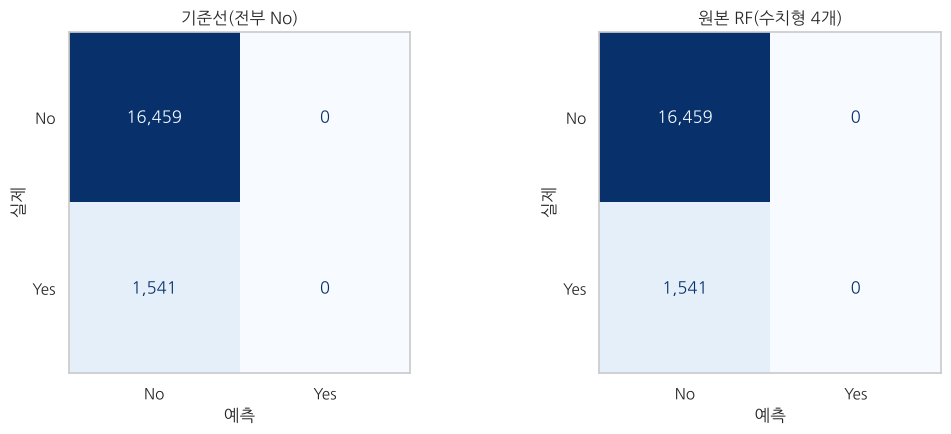

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, pred) in zip(axes, [('기준선(전부 No)', pred_dummy), ('원본 RF(수치형 4개)', pred_orig)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=['No', 'Yes']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',')
    ax.set_title(title)
    ax.set_xlabel('예측'); ax.set_ylabel('실제')
    ax.grid(False)
plt.tight_layout()
plt.show()

* 한줄 확인 : 두 오차행렬이 **완전히 같다.** 실제 환자(Yes) 1,541명 중 찾아낸 사람은 0명.

#### 원본과 똑같이(전체 32만 행, random_state=0) 다시 해 보면?

In [9]:
X_all = df[num_cols]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_all, df['target'], test_size=0.3, random_state=0)
rf_full = RandomForestClassifier(max_depth=4, n_estimators=30, random_state=0, n_jobs=2).fit(Xa_tr, ya_tr)
pred_full = rf_full.predict(Xa_te)

print('테스트 정확도       :', round(accuracy_score(ya_te, pred_full), 4))
print('테스트의 No 비율    :', round((ya_te == 0).mean(), 4))
print('Yes로 예측한 사람 수 :', (pred_full == 1).sum(), '/', len(pred_full))

테스트 정확도       : 0.9144
테스트의 No 비율    : 0.9144
Yes로 예측한 사람 수 : 0 / 95939


* 한줄 확인 : 원본 정확도 **0.9144는 테스트 데이터의 No 비율(0.9144)과 완전히 같다.** 95,939명 중 Yes로 예측한 사람은 **0명** → 원본 모델은 사실상 "전부 No" 기준선이었다.

### 4. 전체 변수 사용 - 범주형 인코딩 Pipeline
 * `ColumnTransformer` : 수치형은 표준화(StandardScaler), 범주형은 OneHot 인코딩
 * `Pipeline` : 전처리 + 모델을 하나로 묶어 **학습 데이터로만 변환 규칙을 학습** (테스트 데이터 정보 누수 방지)
 * 모델 : 로지스틱 회귀, (가벼운) 랜덤포레스트(max_depth=8, n_estimators=100)

In [10]:
num_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']
cat_cols = ['Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking', 'Sex', 'AgeCategory', 'Race',
            'Diabetic', 'PhysicalActivity', 'GenHealth', 'Asthma', 'KidneyDisease', 'SkinCancer']
X_train, X_test = train[num_cols + cat_cols], test[num_cols + cat_cols]

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

def make_model(clf):
    return Pipeline([('prep', preprocess), ('clf', clf)])

print('인코딩 후 열 수:', preprocess.fit(X_train).transform(X_train[:5]).shape[1])

인코딩 후 열 수: 50


* 한줄 확인 : 수치형 4개 + 범주형 13개가 OneHot 인코딩 후 **50개 열**이 되었다.

In [11]:
lr = make_model(LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
proba_lr = lr.predict_proba(X_test)[:, 1]
evaluate('로지스틱 회귀', y_test, lr.predict(X_test), proba_lr)

,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,로지스틱 회귀,0.917,0.113,0.59,0.19,0.838,1367,121


In [12]:
rf = make_model(RandomForestClassifier(max_depth=8, n_estimators=100, random_state=42, n_jobs=2))
rf.fit(X_train, y_train)
proba_rf = rf.predict_proba(X_test)[:, 1]
evaluate('랜덤포레스트', y_test, rf.predict(X_test), proba_rf)

,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,랜덤포레스트,0.916,0.025,0.745,0.048,0.826,1503,13


* 한줄 확인 : 변수를 모두 쓰니 ROC-AUC가 0.663 → **0.838(로지스틱), 0.826(랜덤포레스트)** 로 크게 올랐다. 그런데 임계값 0.5에서는 재현율이 **0.113, 0.025**뿐 → 여전히 환자 대부분을 놓친다. 정확도(0.917, 0.916)는 기준선 0.914와 거의 차이가 없다.

### 5. class_weight - 소수 클래스에 가중치 주기
 * `class_weight='balanced'` : 적은 클래스(Yes)를 틀리면 더 큰 벌점을 준다. (No:Yes ≈ 91.4:8.6 → Yes 한 명의 가중치가 No 한 명의 약 **10.7배**)

In [13]:
lr_bal = make_model(LogisticRegression(max_iter=1000, class_weight='balanced'))
lr_bal.fit(X_train, y_train)
proba_lr_bal = lr_bal.predict_proba(X_test)[:, 1]
evaluate('로지스틱 회귀 + balanced', y_test, lr_bal.predict(X_test), proba_lr_bal)

,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,로지스틱 회귀 + balanced,0.747,0.775,0.221,0.344,0.838,347,4199


In [14]:
rf_bal = make_model(RandomForestClassifier(max_depth=8, n_estimators=100, class_weight='balanced',
                                           random_state=42, n_jobs=2))
rf_bal.fit(X_train, y_train)
proba_rf_bal = rf_bal.predict_proba(X_test)[:, 1]
evaluate('랜덤포레스트 + balanced', y_test, rf_bal.predict(X_test), proba_rf_bal)

,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,랜덤포레스트 + balanced,0.758,0.731,0.222,0.34,0.825,415,3950


* 한줄 확인 : balanced를 쓰면 재현율이 **0.113 → 0.775(로지스틱), 0.025 → 0.731(랜덤포레스트)** 로 크게 오른다. 대신 정밀도는 약 0.22로 내려가고, 정확도는 0.75 정도로 **기준선보다 낮아진다.** → 정확도만 봤다면 "나빠진 모델"로 오해했을 것

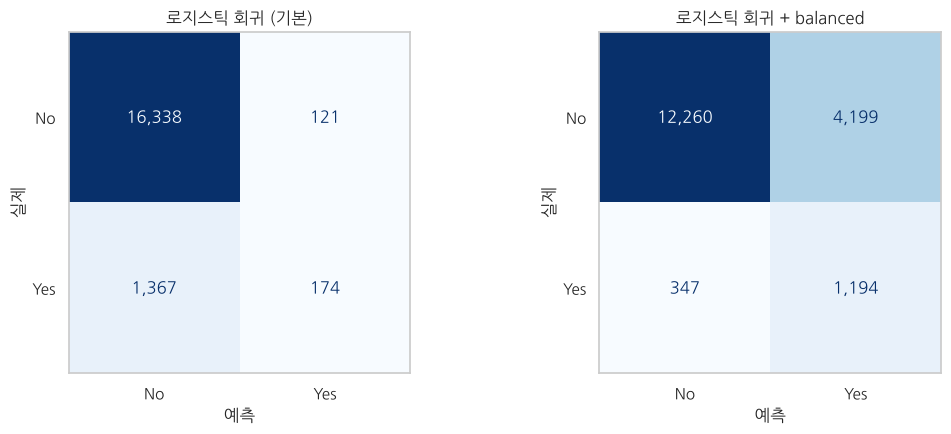

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, model) in zip(axes, [('로지스틱 회귀 (기본)', lr), ('로지스틱 회귀 + balanced', lr_bal)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=['No', 'Yes']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',')
    ax.set_title(title)
    ax.set_xlabel('예측'); ax.set_ylabel('실제')
    ax.grid(False)
plt.tight_layout()
plt.show()

* 한줄 확인 : 놓친 환자(FN)가 **1,367명 → 347명**으로 줄었다. 대신 건강한 사람을 환자로 잡은 오경보(FP)가 121명 → 4,199명으로 늘었다.

### 6. 임계값 조정 - 0.5가 정답은 아니다
 * `predict()`는 확률이 **0.5 이상**이면 Yes로 예측한다. 불균형 데이터에서는 Yes 확률이 0.5를 넘는 사람이 드물다.
 * 임계값을 낮추면 → 재현율 ↑, 정밀도 ↓ (서로 맞바꾸는 관계)
 * 주의 : 실제로는 임계값을 **검증 데이터**로 정해야 한다. 여기서는 학습 데이터의 일부(검증용 20%)로 정한다.

In [16]:
# 학습 데이터를 다시 나누어 검증용 데이터로 임계값 결정 (테스트 데이터는 마지막 평가에만 사용)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                            stratify=y_train, random_state=42)
lr_val = make_model(LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
proba_val = lr_val.predict_proba(X_val)[:, 1]

# 임계값별 재현율, 정밀도, F1 (검증 데이터)
th_table = pd.DataFrame([{'임계값': t,
                          '재현율': recall_score(y_val, proba_val >= t),
                          '정밀도': precision_score(y_val, proba_val >= t, zero_division=0),
                          'F1': f1_score(y_val, proba_val >= t)}
                         for t in np.arange(0.05, 0.55, 0.05).round(2)])
best_th = th_table.loc[th_table['F1'].idxmax(), '임계값']
print('검증 데이터에서 F1이 가장 높은 임계값:', best_th)
th_table.round(3)

검증 데이터에서 F1이 가장 높은 임계값: 0.15


,임계값,재현율,정밀도,F1
0,0.05,0.908,0.173,0.290
1,0.10,0.752,0.234,0.357
2,0.15,0.619,0.299,0.403
3,0.20,0.481,0.347,0.403
4,0.25,0.388,0.399,0.393
5,0.30,0.287,0.421,0.341
6,0.35,0.220,0.470,0.300
7,0.40,0.164,0.511,0.248
8,0.45,0.122,0.557,0.201
9,0.50,0.092,0.589,0.159


* 한줄 확인 : 임계값을 0.5 → 0.05로 낮추면 재현율은 0.092 → 0.908로 오르고 정밀도는 0.589 → 0.173으로 떨어진다. F1은 **0.15(0.403)** 에서 가장 높다. (0.20도 0.403으로 거의 같다)

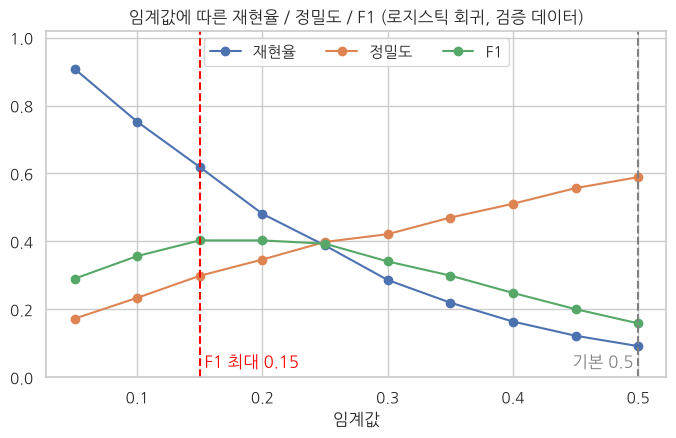

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(th_table['임계값'], th_table['재현율'], marker='o', label='재현율')
ax.plot(th_table['임계값'], th_table['정밀도'], marker='o', label='정밀도')
ax.plot(th_table['임계값'], th_table['F1'], marker='o', label='F1')
ax.axvline(0.5, color='gray', ls='--')
ax.axvline(best_th, color='red', ls='--')
ax.text(0.5, 0.03, '기본 0.5 ', color='gray', ha='right')
ax.text(best_th, 0.03, f' F1 최대 {best_th}', color='red')
ax.set_title('임계값에 따른 재현율 / 정밀도 / F1 (로지스틱 회귀, 검증 데이터)')
ax.set_xlabel('임계값'); ax.set_ylim(0, 1.02)
ax.legend(loc='upper center', ncol=3)
plt.show()

* 한줄 확인 : 재현율과 정밀도는 서로 반대로 움직인다. 기본값 0.5는 표에서 F1이 **가장 낮은(0.159)** 임계값이다.

In [18]:
# 검증에서 정한 임계값을 테스트 데이터에 적용 (모델은 전체 학습 데이터로 학습한 lr 사용)
pred_lr_th = (proba_lr >= best_th).astype(int)
evaluate(f'로지스틱 회귀 + 임계값 {best_th}', y_test, pred_lr_th, proba_lr)

,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,로지스틱 회귀 + 임계값 0.15,0.84,0.591,0.288,0.387,0.838,631,2250


In [19]:
# 재현율을 더 중시하는 경우 : 임계값 0.1
pred_lr_01 = (proba_lr >= 0.1).astype(int)
evaluate('로지스틱 회귀 + 임계값 0.1', y_test, pred_lr_01, proba_lr)

,모델,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
0,로지스틱 회귀 + 임계값 0.1,0.773,0.733,0.235,0.356,0.838,412,3667


* 한줄 확인 : 같은 로지스틱 회귀 모델이라도 임계값만 0.15로 바꾸면 재현율 0.113 → **0.591**, F1 0.190 → **0.387**. 임계값 0.1이면 재현율 **0.733**으로 balanced(0.775)와 비슷한 수준이 된다. (ROC-AUC는 확률 순서만 보므로 0.838 그대로)

#### ROC 곡선 - 임계값과 상관없는 비교

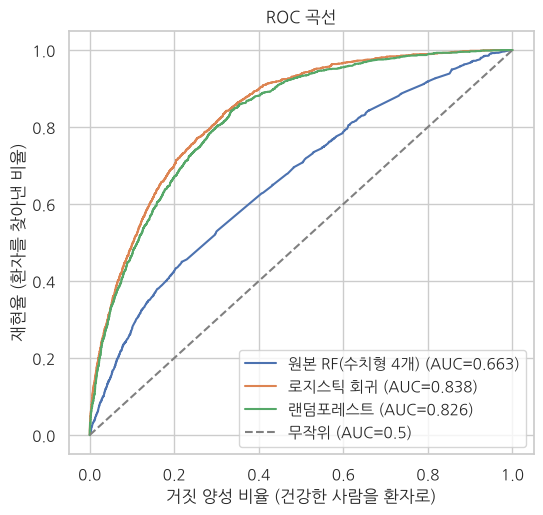

In [20]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, p in [('원본 RF(수치형 4개)', proba_orig), ('로지스틱 회귀', proba_lr), ('랜덤포레스트', proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
ax.plot([0, 1], [0, 1], color='gray', ls='--', label='무작위 (AUC=0.5)')
ax.set_xlabel('거짓 양성 비율 (건강한 사람을 환자로)')
ax.set_ylabel('재현율 (환자를 찾아낸 비율)')
ax.set_title('ROC 곡선')
ax.legend(loc='lower right')
plt.show()

* 한줄 확인 : 원본 모델(AUC 0.663)보다 전체 변수 모델(0.838, 0.826)이 모든 구간에서 위에 있다. 이 데이터에서는 가벼운 랜덤포레스트보다 **로지스틱 회귀가 조금 더 좋다.**

### 7. 정리

In [21]:
summary = pd.DataFrame(results).drop_duplicates('모델').set_index('모델').round(3)
summary

,정확도,재현율,정밀도,F1,ROC-AUC,놓친 환자(FN),오경보(FP)
모델,,,,,,,
기준선(전부 No),0.914,0.000,0.000,0.000,0.500,1541,0
원본 RF(수치형 4개),0.914,0.000,0.000,0.000,0.663,1541,0
로지스틱 회귀,0.917,0.113,0.590,0.190,0.838,1367,121
랜덤포레스트,0.916,0.025,0.745,0.048,0.826,1503,13
로지스틱 회귀 + balanced,0.747,0.775,0.221,0.344,0.838,347,4199
랜덤포레스트 + balanced,0.758,0.731,0.222,0.340,0.825,415,3950
로지스틱 회귀 + 임계값 0.15,0.840,0.591,0.288,0.387,0.838,631,2250
로지스틱 회귀 + 임계값 0.1,0.773,0.733,0.235,0.356,0.838,412,3667


* 한줄 확인 : 정확도가 가장 높은 모델(로지스틱 회귀 0.917)은 환자를 **1,367명** 놓친다. 환자를 찾는 목적이라면 **balanced 또는 임계값 조정** 모델을 선택해야 하며, F1 기준으로는 **로지스틱 회귀 + 임계값 0.15(0.387)** 가 가장 좋다. (놓친 환자 631명, 오경보 2,250명)

| 질문 | 기본 분석 | 추가 분석 결과 |
|---|---|---|
| 정확도 0.914는 좋은 성능일까? | 랜덤포레스트 테스트 정확도 0.914 | 전부 No 기준선도 0.914. 원본 모델은 95,939명 중 **Yes 예측 0명** |
| mse/rmse로 평가해도 될까? | mse 0.0856, rmse 0.2925 | 0/1 분류에서 mse = 1 - 정확도. 오류의 종류를 알 수 없으므로 **오차행렬, 재현율, 정밀도** 사용 |
| 범주형 변수를 쓰면? | 수치형 4개만 사용 | OneHot Pipeline으로 50개 열, ROC-AUC **0.663 → 0.838** (로지스틱 회귀) |
| 환자를 얼마나 찾아낼까? | 재현율 0 | 임계값 0.5에서 0.113 → balanced **0.775** / 임계값 0.15 **0.591**, 임계값 0.1 **0.733** |
| 어떤 모델이 좋을까? | 랜덤포레스트 | 가벼운 랜덤포레스트(AUC 0.826)보다 **로지스틱 회귀(0.838)** 가 조금 더 좋고 해석도 쉽다 |

#### 배운 점
 * 불균형 데이터에서는 먼저 **기준선(가장 많은 클래스로만 예측)** 의 정확도를 구하고 비교한다.
 * 분류 모델은 **오차행렬**을 꼭 보고, 목적에 맞는 지표(의료 선별 → 재현율, F1)로 평가한다.
 * `class_weight`와 **임계값 조정**은 모델을 바꾸지 않고도 재현율을 크게 올린다. 대신 정밀도(오경보)와 맞바꾸는 것이므로 **얼마나 놓쳐도 되는지**를 먼저 정해야 한다.
 * 임계값은 테스트 데이터가 아닌 **검증 데이터**로 정한다.

#### 다음에 해 볼 분석
 * 어떤 요인이 심장병 위험을 높이는지 → [추가 분석 2편 - 위험 요인 분석](https://ldjwj.github.io/dataAnalysis/01_10C_Heart_Disease_Risk_Factors.html)
 * 전체 데이터로 다시 학습하고, 교차 검증(StratifiedKFold)으로 임계값과 성능의 안정성 확인
 * HistGradientBoosting 등 다른 트리 모델, PR-AUC(Average Precision) 지표 비교